# Task 3: Alternative Clustering Methods
We cluster MPs by how they vote with DBSCAN and Spectral Clustering, compare the result with Louvain and with the real parties, and check how sensitive and stable the clusters are.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

MIN_VOTES = 200         # minimum number of present votes (For/Against/Abstain) to keep an MP
DROP_UNANIMOUS = False  # drop sessions where one side has at least UNANIMOUS of the For/Against votes
UNANIMOUS = 0.95

## 1. Load, encode and filter
We build an MP × session matrix with the encoding:

| Vote | Value |
|---|---|
| For | +1 |
| Against | −1 |
| Abstain | 0 |
| Absent | NaN (ignored) |

About 40% of all ballots are absences. In the Folketinget, absences are largely arranged between parties (*clearing*), so they say little about an MP's position, and we leave them out instead of treating them as a vote. Substitutes and MPs who joined or left during the period have few votes, so we keep only MPs with at least `MIN_VOTES` present votes. This filter is applied before the (optional) removal of near-unanimous sessions, so the set of MPs does not depend on `DROP_UNANIMOUS`.

An MP can belong to several parties over the period, so we label each MP with the party they voted for most often.

In [2]:
df = pd.read_csv("votes.csv", parse_dates=["date"])
assert not df.duplicated(["actor", "session"]).any()

X = (df.assign(vote=df["vote"].map({1: 1, 2: -1, 3: np.nan, 4: 0}))
       .pivot(index="actor", columns="session", values="vote"))

present = X.notna().sum(axis=1)
X = X[present >= MIN_VOTES]

if DROP_UNANIMOUS:
    yes_no = df[df["vote"].isin([1, 2])]
    majority = yes_no.groupby("session")["vote"].agg(lambda v: max((v == 1).mean(), (v == 2).mean()))
    X = X.drop(columns=majority[majority >= UNANIMOUS].index)

party = (df.dropna(subset=["party"])
           .groupby("actor")["party"]
           .agg(lambda p: p.value_counts().index[0])
           .reindex(X.index))

print(f"{len(X)} MPs (dropped {(present < MIN_VOTES).sum()}), {X.shape[1]} sessions")
party.value_counts()

181 MPs (dropped 16), 1302 sessions


party
Socialdemokratiet                                     52
Venstre, Danmarks Liberale Parti                      23
Socialistisk Folkeparti                               16
Danmarksdemokraterne – Inger Støjberg                 15
Moderaterne                                           15
Liberal Alliance                                      14
Det Konservative Folkeparti                           12
Enhedslisten                                          11
Dansk Folkeparti                                       7
Radikale Venstre                                       6
Alternativet                                           6
Uden for folketingsgrupperne - Lars Boje Mathiesen     1
Uden for folketingsgrupperne - Theresa Scavenius       1
Uden for folketingsgrupperne - Jon Stephensen          1
Uden for folketingsgrupperne - Mike Villa Fonseca      1
Name: count, dtype: int64

In [3]:
df

,session,actor,vote,conclusion,passed,date,party
0,9002,220,1,"Forslaget blev vedtaget. For stemte 112 (S, V,...",True,2022-11-16 13:00:00,Socialdemokratiet
1,9002,121,1,"Forslaget blev vedtaget. For stemte 112 (S, V,...",True,2022-11-16 13:00:00,Socialistisk Folkeparti
2,9002,93,1,"Forslaget blev vedtaget. For stemte 112 (S, V,...",True,2022-11-16 13:00:00,"Venstre, Danmarks Liberale Parti"
3,9002,120,1,"Forslaget blev vedtaget. For stemte 112 (S, V,...",True,2022-11-16 13:00:00,Socialdemokratiet
4,9002,34,1,"Forslaget blev vedtaget. For stemte 112 (S, V,...",True,2022-11-16 13:00:00,Danmarksdemokraterne – Inger Støjberg
...,...,...,...,...,...,...,...
219406,10378,80,3,"Vedtaget\nFor stemte 93 (S, V, DD, SF, LA, M, ...",True,2025-09-30 13:00:00,"Venstre, Danmarks Liberale Parti"
219407,10378,18696,1,"Vedtaget\nFor stemte 93 (S, V, DD, SF, LA, M, ...",True,2025-09-30 13:00:00,"Venstre, Danmarks Liberale Parti"
219408,10378,18701,3,"Vedtaget\nFor stemte 93 (S, V, DD, SF, LA, M, ...",True,2025-09-30 13:00:00,"Venstre, Danmarks Liberale Parti"
219409,10378,18716,3,"Vedtaget\nFor stemte 93 (S, V, DD, SF, LA, M, ...",True,2025-09-30 13:00:00,Socialdemokratiet


## 2. Agreement matrix
For every pair of MPs we count the sessions where both were present (`N`) and the share of those sessions where they voted the same way (`A`, the agreement rate). `D = 1 − A` is the distance used by DBSCAN, and `A` is the affinity used by Spectral Clustering and Louvain.

In [4]:
V = X.to_numpy()
M = (~np.isnan(V)).astype(float)

N = M @ M.T
agree = sum((V == k).astype(float) @ (V == k).T.astype(float) for k in (1, -1, 0))
with np.errstate(invalid="ignore", divide="ignore"):
    A = agree / N
D = 1 - A

print(A.shape, f"agreement rate: mean {np.nanmean(A):.3f}, min {np.nanmin(A):.3f}")

(181, 181) agreement rate: mean 0.748, min 0.000


### Pairs with few shared votes
The agreement rate of two MPs who rarely voted in the same session is unreliable (or undefined when `N = 0`), for example a substitute and the MP they replaced.

In [5]:
iu = np.triu_indices(len(X), k=1)
pairs = pd.DataFrame({
    "mp1":    X.index[iu[0]],
    "mp2":    X.index[iu[1]],
    "shared": N[iu].astype(int),
    "agree":  A[iu],
})
pairs["party1"] = pairs["mp1"].map(party)
pairs["party2"] = pairs["mp2"].map(party)

print(f"pairs: {len(pairs)}, with 0 shared votes: {(pairs['shared'] == 0).sum()}, "
      f"with < 30 shared votes: {(pairs['shared'] < 30).sum()}")
pairs[pairs["shared"] < 30].sort_values("shared")

pairs: 16290, with 0 shared votes: 129, with < 30 shared votes: 208


,mp1,mp2,shared,agree,party1,party2
5988,181,20925,0,NaN,Socialdemokratiet,Det Konservative Folkeparti
5989,181,20930,0,NaN,Socialdemokratiet,Socialdemokratiet
5990,181,20962,0,NaN,Socialdemokratiet,Socialistisk Folkeparti
5991,181,20966,0,NaN,Socialdemokratiet,Det Konservative Folkeparti
5993,181,21083,0,NaN,Socialdemokratiet,Socialdemokratiet
...,...,...,...,...,...,...
7762,238,20580,29,0.620690,Dansk Folkeparti,Moderaterne
6130,182,20841,29,0.655172,Danmarksdemokraterne – Inger Støjberg,Moderaterne
4193,134,20841,29,0.689655,Radikale Venstre,Moderaterne
14396,20354,20966,29,0.172414,Uden for folketingsgrupperne - Theresa Scavenius,Det Konservative Folkeparti


> **To decide:** how to treat these pairs (e.g. distance 1 / affinity 0, or a minimum overlap).

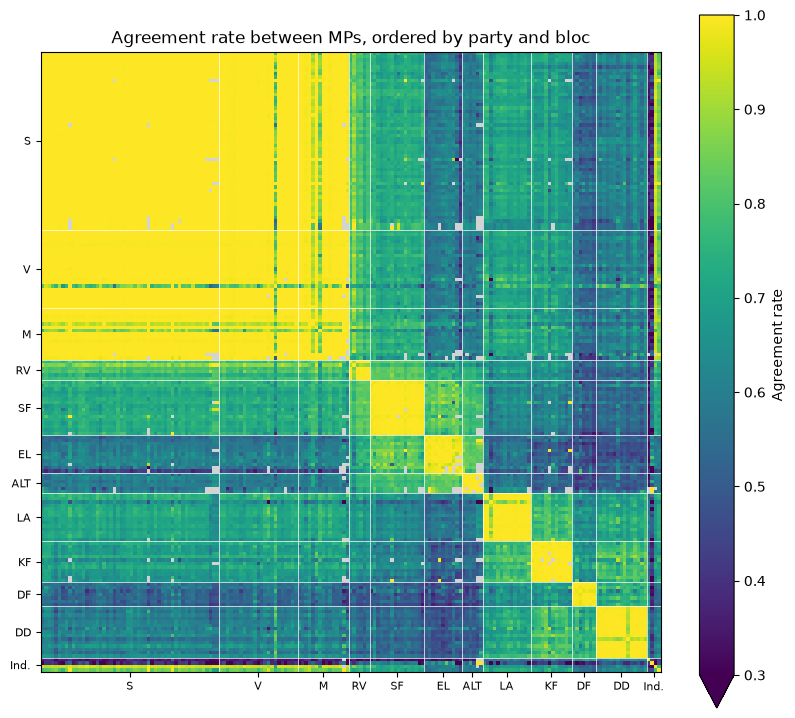

In [6]:
ABBR = {
    "Socialdemokratiet":                     "S",
    "Venstre, Danmarks Liberale Parti":      "V",
    "Moderaterne":                           "M",
    "Radikale Venstre":                      "RV",
    "Socialistisk Folkeparti":               "SF",
    "Enhedslisten":                          "EL",
    "Alternativet":                          "ALT",
    "Liberal Alliance":                      "LA",
    "Det Konservative Folkeparti":           "KF",
    "Dansk Folkeparti":                      "DF",
    "Danmarksdemokraterne – Inger Støjberg": "DD",
}
BLOCS = ["S", "V", "M", "RV", "SF", "EL", "ALT", "LA", "KF", "DF", "DD", "Ind."]  # government, RV, left, right, independents

short = party.map(ABBR).mask(party.str.startswith("Uden for folketingsgrupperne"), "Ind.").fillna(party)
rank = short.map({p: i for i, p in enumerate(BLOCS)}).fillna(len(BLOCS))  # unknown parties go last
order = pd.DataFrame({"rank": rank, "short": short}).sort_values(["rank", "short"]).index

idx = X.index.get_indexer(order)
labels = short[order].to_numpy()
groups = pd.unique(labels)
bounds = np.flatnonzero(labels[1:] != labels[:-1]) + 0.5
centers = [np.flatnonzero(labels == p).mean() for p in groups]

cmap = plt.get_cmap("viridis").copy()
cmap.set_bad("lightgrey")

fig, ax = plt.subplots(figsize=(10, 9))
im = ax.imshow(A[np.ix_(idx, idx)], cmap=cmap, vmin=0.3, vmax=1)
for b in bounds:
    ax.axhline(b, color="white", lw=0.5)
    ax.axvline(b, color="white", lw=0.5)
ax.set_xticks(centers, groups, fontsize=8)
ax.set_yticks(centers, groups, fontsize=8)
ax.set_title("Agreement rate between MPs, ordered by party and bloc")
fig.colorbar(im, ax=ax, label="Agreement rate", extend="min")
plt.show()

## Sankey: parties → clusters
A Sankey diagram shows how the members of each party are spread over the clusters: a party that maps to a single cluster is one thick band, a party split across clusters fans out, and a thin band leaving a party points to possible mavericks. `sankey(left, right)` takes any two labelings of the MPs, so the same plot can compare parties, DBSCAN, Spectral and Louvain.

> Placeholder: the clusters below come from a quick Spectral Clustering on `A` (undefined pairs set to 0) with `k = 8`, until the final settings are chosen.

Clusters have no names of their own: each one is labelled with the parties that make up at least 20% of its members, followed by its size.

In [7]:
import plotly.graph_objects as go
from sklearn.cluster import SpectralClustering

def sankey(left, right, title=""):
    flows = pd.crosstab(left, right).stack().loc[lambda s: s > 0]
    l_nodes = [str(a) for a in pd.unique(left) if a in flows.index.get_level_values(0)]
    r_nodes = [str(b) for b in sorted(pd.unique(right))]
    nodes = l_nodes + r_nodes
    src = [nodes.index(str(a)) for a, _ in flows.index]
    tgt = [len(l_nodes) + r_nodes.index(str(b)) for _, b in flows.index]
    fig = go.Figure(go.Sankey(
        node=dict(label=nodes, pad=10, thickness=15),
        link=dict(source=src, target=tgt, value=flows.to_numpy()),
    ))
    fig.update_layout(title=title, height=600, font_size=11)
    fig.show()

spec = SpectralClustering(n_clusters=8, affinity="precomputed", random_state=0)
clusters = pd.Series(spec.fit_predict(np.nan_to_num(A, nan=0)), index=X.index)

def name_clusters(clusters, min_share=0.2):
    names = {}
    for c, members in short.groupby(clusters):
        counts = members.value_counts()
        names[c] = f"{c}: " + "+".join(counts.index[counts / len(members) >= min_share]) + f" ({len(members)})"
    return clusters.map(names)

clusters = name_clusters(clusters)

sankey(short[order], clusters[order], "Party → Spectral cluster")

## 3. DBSCAN
We look for groups of MPs that vote alike **without** telling the algorithm how many groups there are or which party anyone belongs to. DBSCAN fits this question well:
- the number of clusters is not given in advance (12 party labels does not mean 12 voting groups);
- MPs who vote like nobody else are left as **noise** instead of being forced into a cluster, so noise points are natural maverick candidates;
- it only needs distances between MPs, so it can use the agreement matrix directly and never has to fill in absent votes.

Outline: 3.1 distances and features, 3.2 choosing ε and MinPts, 3.3 scikit-learn version, 3.4 our own implementation, 3.5 comparison of the two, 3.6 evaluation against k-means, 3.7 MPs outside their party's cluster.

In [8]:
import time
from sklearn.cluster import DBSCAN, KMeans
from sklearn.datasets import make_moons
from sklearn.decomposition import PCA
from sklearn.impute import KNNImputer
from sklearn.metrics import (adjusted_rand_score, davies_bouldin_score,
                             pairwise_distances, silhouette_score)

MIN_SHARED = 100  # minimum number of shared votes for a pair's agreement rate to be trusted
EPS = 0.03        # neighbours disagree in at most 3% of their shared votes
MIN_PTS = 4       # neighbours needed to be a core point (the point itself counts)

### 3.1 Distances and features
**Distance for DBSCAN.** We use `D = 1 − A`, the share of shared votes where two MPs disagree. It is between 0 and 1 for every pair, so no scaling is needed.

Pairs with few shared votes are a problem for DBSCAN in particular: two MPs from different parties who happened to agree in 5 shared votes get distance 0 and become a bridge that chains two clusters together. Pairs with fewer than `MIN_SHARED` shared votes therefore get the maximum distance 1, so they can never be neighbours. The value 100 comes from the standard-error argument in `retrieve.ipynb` (SE ≤ 0.05).

In [9]:
def shared_distance(min_shared):
    dist = np.where(N >= min_shared, D, 1.0)
    np.fill_diagonal(dist, 0)
    return dist

rows = []
for m in (1, 30, 50, 100):
    lab = DBSCAN(eps=EPS, min_samples=MIN_PTS, metric="precomputed").fit_predict(shared_distance(m))
    sizes = np.bincount(lab[lab >= 0])
    rows.append({
        "min_shared":      m,
        "clusters":        len(sizes),
        "noise":           (lab == -1).sum(),
        "largest cluster": sizes.max(),
        "parties in it":   ", ".join(pd.unique(short[lab == sizes.argmax()])),
    })

dist = shared_distance(MIN_SHARED)
pd.DataFrame(rows)

,min_shared,clusters,noise,largest cluster,parties in it
0,1,5,2,139,"S, V, M, EL, SF, RV, KF, ALT, Ind."
1,30,9,2,93,"S, V, M, RV, Ind."
2,50,9,2,93,"S, V, M, RV, Ind."
3,100,9,2,93,"S, V, M, RV, Ind."


Without the rule, a few unreliable pairs chain S, V, M, SF, EL, KF and ALT into one cluster of 139 MPs. Any threshold from 30 up separates them in the same way, so the result does not depend on the exact value.

**Vectors for k-means, Davies-Bouldin and the plots.** These need coordinates, so here the absent votes have to be filled in. Writing 0 for them would make MPs look similar just because they are often absent, so we fill each absent vote with the average vote of the 5 most similar MPs who were present (`KNNImputer`). It never looks at party labels.

All columns are already on the same scale (−1 to +1). We do not use `StandardScaler`: it would divide near-unanimous sessions by a tiny standard deviation and give a lot of weight to the sessions that separate MPs the least.

A For/Against disagreement contributes $(1-(-1))^2 = 4$ to the squared Euclidean distance, so on these vectors $\lVert x-y\rVert^2 \approx 4 \cdot n_{sessions} \cdot D(x,y)$. This lets us translate ε between the two representations.

In [10]:
Z = KNNImputer(n_neighbors=5).fit_transform(X)
dist_Z = pairwise_distances(Z)
eps_Z = np.sqrt(4 * Z.shape[1] * EPS)

pca = PCA(n_components=2).fit(Z)
xy = pca.transform(Z)  # only used for plotting

iu = np.triu_indices(len(X), k=1)
trusted = N[iu] >= MIN_SHARED
corr = np.corrcoef(dist[iu][trusted], dist_Z[iu][trusted] ** 2)[0, 1]
print(f"Z: {Z.shape}, eps on Z = {eps_Z:.2f}, correlation with D = {corr:.3f}, "
      f"variance in 2 components = {pca.explained_variance_ratio_.sum():.2f}")

Z: (181, 1302), eps on Z = 12.50, correlation with D = 0.959, variance in 2 components = 0.71


### 3.2 Choosing ε and MinPts
**MinPts = 4.** RV and ALT have only 6 MPs each in our data, so MinPts must stay below 6 or these groups could hardly form a cluster. Values that are too low (1–2) would turn pairs of MPs into clusters.

**ε from the k-distance plot.** For each MP we take the distance to the 4th closest MP (counting the MP itself, like MinPts does): this is the smallest ε that makes the MP a core point. Sorted, the curve shows where the dense areas end.

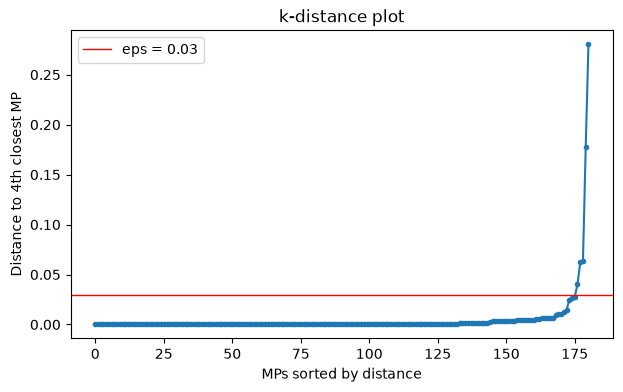

97.2% of the MPs are core points for eps = 0.03


In [11]:
k_dist = np.sort(np.sort(dist, axis=1)[:, MIN_PTS - 1])

plt.figure(figsize=(7, 4))
plt.plot(k_dist, marker=".")
plt.axhline(EPS, color="red", lw=1, label=f"eps = {EPS}")
plt.xlabel("MPs sorted by distance")
plt.ylabel(f"Distance to {MIN_PTS}th closest MP")
plt.title("k-distance plot")
plt.legend()
plt.show()

print(f"{(k_dist <= EPS).mean():.1%} of the MPs are core points for eps = {EPS}")

The curve stays close to zero (party discipline is very strong) and bends up sharply for the last few MPs. The elbow gives a range rather than one value, so we also check how the result changes over a grid.

In [12]:
eps_grid = [0.003, 0.005, 0.01, 0.02, 0.03, 0.04, 0.05, 0.08, 0.10, 0.12, 0.15]
sweep = pd.DataFrame(index=eps_grid, columns=[3, 4, 5, 6, 8])
for e in sweep.index:
    for m in sweep.columns:
        lab = DBSCAN(eps=e, min_samples=m, metric="precomputed").fit_predict(dist)
        sweep.loc[e, m] = f"{lab.max() + 1} / {(lab == -1).sum()}"

print("number of clusters / number of noise points")
sweep.rename_axis(index="eps", columns="MinPts")

number of clusters / number of noise points


MinPts,3,4,5,6,8
eps,,,,,
0.003,9 / 11,7 / 19,7 / 22,6 / 29,5 / 38
0.005,9 / 8,9 / 8,9 / 9,7 / 20,5 / 36
0.010,9 / 4,9 / 4,9 / 5,8 / 11,6 / 24
0.020,9 / 2,9 / 2,9 / 3,8 / 8,6 / 21
0.030,9 / 2,9 / 2,9 / 3,8 / 8,6 / 21
0.040,9 / 2,9 / 2,9 / 3,8 / 8,6 / 21
0.050,9 / 1,9 / 1,9 / 2,8 / 7,6 / 20
0.080,7 / 1,7 / 1,7 / 2,7 / 7,5 / 19
0.100,5 / 1,5 / 1,5 / 1,5 / 2,4 / 13


With MinPts between 3 and 5 we get the same 9 clusters and 1–5 noise points for every ε from 0.01 to 0.05, and `EPS = 0.03` lies in the middle of this plateau.
- **ε too small** (below 0.005): small parties turn into noise.
- **ε too large** (from 0.08): neighbouring parties are chained together until almost everyone is in one cluster.
- **MinPts too large** (6 and up): RV cannot form a cluster any more, because only 5 of its MPs vote together.

MinPts = 4 is not a neutral choice: we use our knowledge of how small the parties are. ε is only read from the votes.

### 3.3 scikit-learn DBSCAN
Same steps as in the clustering exercise (Exercise 2): create the model, fit it, read `labels_`. The only difference is `metric="precomputed"`, since we pass distances instead of 2D points. Label −1 means noise.

In [13]:
dbscan_sk = DBSCAN(eps=EPS, min_samples=MIN_PTS, metric="precomputed")
dbscan_sk.fit(dist)

print("clusters:", dbscan_sk.labels_.max() + 1, "| noise:", (dbscan_sk.labels_ == -1).sum())
pd.crosstab(short, dbscan_sk.labels_, rownames=["party"], colnames=["cluster"]).reindex(BLOCS)

clusters: 9 | noise: 2


cluster,-1,0,1,2,3,4,5,6,7,8
party,,,,,,,,,,
S,0,0,0,52,0,0,0,0,0,0
V,0,0,0,23,0,0,0,0,0,0
M,0,0,0,15,0,0,0,0,0,0
RV,0,0,0,1,0,0,5,0,0,0
SF,0,0,0,0,0,0,0,16,0,0
EL,0,0,0,0,0,11,0,0,0,0
ALT,0,0,0,0,0,0,0,0,0,6
LA,0,0,0,0,14,0,0,0,0,0
KF,0,0,0,0,0,0,0,0,12,0


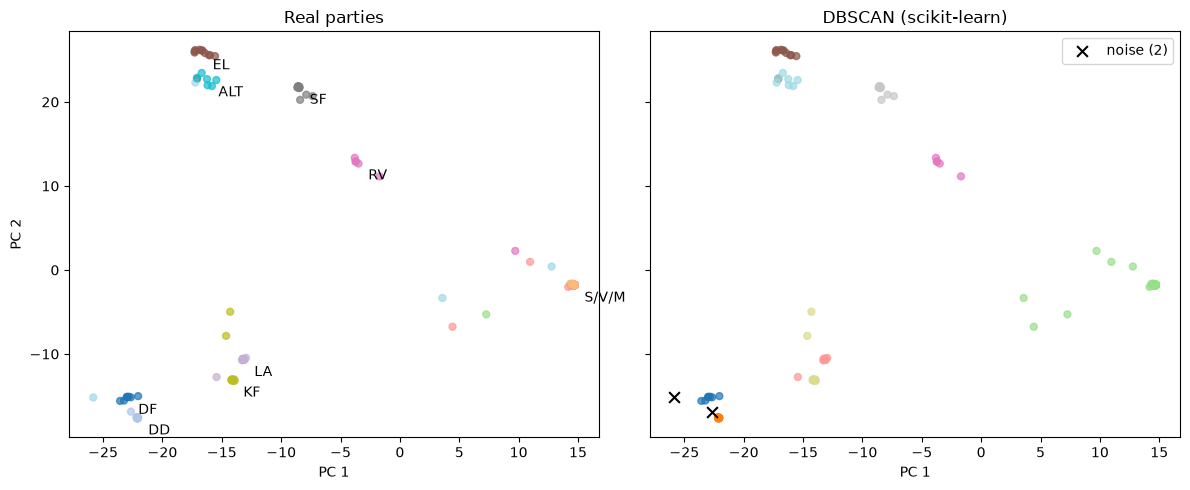

In [14]:
def plot_labels(ax, labels, title):
    noise = labels == -1
    ax.scatter(xy[~noise, 0], xy[~noise, 1], c=labels[~noise], cmap="tab20", s=25, alpha=0.7)
    ax.scatter(xy[noise, 0], xy[noise, 1], c="black", marker="x", s=60, label=f"noise ({noise.sum()})")
    ax.set_title(title)
    ax.set_xlabel("PC 1")
    if noise.any():
        ax.legend()

fig, axs = plt.subplots(ncols=2, figsize=(12, 5), sharey=True)
plot_labels(axs[0], pd.factorize(short)[0], "Real parties")
for p in BLOCS[2:-1]:
    name = "S/V/M" if p == "M" else p  # the three government parties lie on top of each other
    axs[0].annotate(name, np.median(xy[short == p], axis=0), xytext=(8, -12), textcoords="offset points")
plot_labels(axs[1], dbscan_sk.labels_, "DBSCAN (scikit-learn)")
axs[0].set_ylabel("PC 2")
plt.tight_layout()
plt.show()

### 3.4 Our own DBSCAN
We implement the algorithm from the Week 6 slides (52–59), in the spirit of Exercise 4 where k-means was written by hand:
- `region_query`: the ε-neighbourhood of a point, $\{x : d(p, x) \le \varepsilon\}$;
- `expand_cluster`: collects everything reachable from a core point;
- `dbscan`: visits each unvisited point and starts a cluster if it is core.

A point is **core** if its neighbourhood (including itself) has at least MinPts points. A **rim** point is in a cluster without being core, and **noise** keeps the label −1.

In [15]:
def region_query(dist, p, eps):
    return np.flatnonzero(dist[p] <= eps)  # includes p itself


def expand_cluster(dist, p, c, labels, visited, eps, min_pts):
    labels[p] = c
    queue = [p]
    while queue:
        q = queue.pop()
        neighbours = region_query(dist, q, eps)
        if len(neighbours) < min_pts:
            continue  # rim point: in the cluster, but nothing is reachable through it

        # still -1 means unvisited, or visited earlier and thought to be noise
        new = neighbours[labels[neighbours] == -1]
        labels[new] = c
        visited[new] = True
        queue.extend(new)


def dbscan(dist, eps, min_pts):
    n = len(dist)
    labels = np.full(n, -1)  # everything is noise until some cluster reaches it
    visited = np.zeros(n, dtype=bool)
    c = 0

    for p in range(n):
        if visited[p]:
            continue
        visited[p] = True

        if len(region_query(dist, p, eps)) >= min_pts:
            expand_cluster(dist, p, c, labels, visited, eps, min_pts)
            c += 1

    return labels

In [16]:
labels_own = dbscan(dist, EPS, MIN_PTS)

is_core = np.array([len(region_query(dist, p, EPS)) >= MIN_PTS for p in range(len(dist))])
is_noise = labels_own == -1
is_rim = ~is_core & ~is_noise

print(f"clusters: {labels_own.max() + 1} | core: {is_core.sum()}, rim: {is_rim.sum()}, noise: {is_noise.sum()}")

clusters: 9 | core: 176, rim: 3, noise: 2


### 3.5 Own version vs. scikit-learn
**Same result?** We compare both on the same data and parameters, for the disagreement distances and for the vectors `Z`.

In [17]:
rows = []
for name, d_matrix, e in [("D (agreement)", dist, EPS), ("Z (Euclidean)", dist_Z, eps_Z)]:
    own = dbscan(d_matrix, e, MIN_PTS)
    sk = DBSCAN(eps=e, min_samples=MIN_PTS, metric="precomputed").fit(d_matrix)
    core = (d_matrix <= e).sum(axis=1) >= MIN_PTS
    rows.append({
        "data":             name,
        "clusters own":     own.max() + 1,
        "clusters sklearn": sk.labels_.max() + 1,
        "noise own":        (own == -1).sum(),
        "noise sklearn":    (sk.labels_ == -1).sum(),
        "same core points": np.array_equal(np.flatnonzero(core), sk.core_sample_indices_),
        "same labels":      np.array_equal(own, sk.labels_),
        "ARI":              adjusted_rand_score(own, sk.labels_),
    })
pd.DataFrame(rows).set_index("data").T

data,D (agreement),Z (Euclidean)
clusters own,9,9
clusters sklearn,9,9
noise own,2,8
noise sklearn,2,8
same core points,True,True
same labels,True,True
ARI,1.0,1.0


**Runtime.** Our 181 MPs are too few to see how the running time grows, so besides our data we use 2D points (two moons) of increasing size. Our version has to compute all pairwise distances, while scikit-learn can search neighbours with a tree.

In [18]:
def best_time(f, repeat=5):
    times = []
    for _ in range(repeat):
        start = time.perf_counter()
        f()
        times.append(time.perf_counter() - start)
    return 1000 * min(times)

print(f"our data (n = {len(dist)}): own {best_time(lambda: dbscan(dist, EPS, MIN_PTS)):.1f} ms, "
      f"sklearn {best_time(lambda: DBSCAN(eps=EPS, min_samples=MIN_PTS, metric='precomputed').fit(dist)):.1f} ms")

rows = []
for n in (500, 1000, 2000, 4000, 8000):
    points, _ = make_moons(n, noise=0.05, random_state=42)
    own = dbscan(pairwise_distances(points), 0.1, MIN_PTS)
    sk = DBSCAN(eps=0.1, min_samples=MIN_PTS).fit_predict(points)
    rows.append({
        "n":            n,
        "own (ms)":     best_time(lambda: dbscan(pairwise_distances(points), 0.1, MIN_PTS), repeat=3),
        "sklearn (ms)": best_time(lambda: DBSCAN(eps=0.1, min_samples=MIN_PTS).fit(points), repeat=3),
        "ARI":          adjusted_rand_score(own, sk),
    })
pd.DataFrame(rows).round(1)

our data (n = 181): own 0.8 ms, sklearn 1.0 ms


,n,own (ms),sklearn (ms),ARI
0,500,4.5,1.6,1.0
1,1000,12.5,2.8,1.0
2,2000,45.3,6.4,1.0
3,4000,167.4,16.9,1.0
4,8000,729.0,55.7,1.0


The results are identical and on our data there is no practical difference. For larger n our time grows about 4 times when n doubles, as expected for $O(n^2)$: `region_query` scans all n points, and it is called once per point (plus the distance matrix takes $n^2$ memory). scikit-learn is faster because a tree lets it look only at nearby points in 2D. This is not a better worst case: if ε is so large that every point is a neighbour of every other point, the neighbourhoods alone have $n^2$ entries. With a precomputed matrix, as for our MPs, scikit-learn has to scan rows too.

### 3.6 Evaluation and comparison with k-means
As in Exercise 3 we use the Davies-Bouldin index (lower is better), plus the silhouette score (higher is better), both computed on `Z`. Noise is not a cluster, so noise points are excluded. Because this removes the hardest MPs for DBSCAN only, the column *DBI, same MPs* evaluates each method after also leaving out the MPs that are noise for DBSCAN on D.

k-means runs on the vectors `Z`; to compare on exactly the same features, DBSCAN is also run on `Z`.

In [19]:
def evaluate(name, labels):
    ok = labels != -1
    both = ok & ~is_noise
    return {
        "method":         name,
        "clusters":       len(np.unique(labels[ok])),
        "noise":          (~ok).sum(),
        "DBI":            davies_bouldin_score(Z[ok], labels[ok]),
        "DBI, same MPs":  davies_bouldin_score(Z[both], labels[both]),
        "silhouette":     silhouette_score(Z[ok], labels[ok]),
        "ARI vs DBSCAN":  adjusted_rand_score(labels_own, labels),
        "ARI vs parties": adjusted_rand_score(short, labels),
    }

labels_Z = dbscan(dist_Z, eps_Z, MIN_PTS)
rows = [evaluate("DBSCAN on D", labels_own), evaluate("DBSCAN on Z", labels_Z)]
kmeans = {}
for k in range(6, 13):
    kmeans[k] = KMeans(n_clusters=k, n_init=10, random_state=42).fit(Z).labels_
    rows.append(evaluate(f"k-means, k = {k}", kmeans[k]))
pd.DataFrame(rows).set_index("method").round(3)

,clusters,noise,DBI,"DBI, same MPs",silhouette,ARI vs DBSCAN,ARI vs parties
method,,,,,,,
DBSCAN on D,9,2,0.417,0.417,0.830,1.000,0.536
DBSCAN on Z,9,8,0.410,0.410,0.864,0.928,0.568
"k-means, k = 6",6,0,0.640,0.625,0.757,0.957,0.508
"k-means, k = 7",7,0,0.500,0.477,0.795,0.974,0.521
"k-means, k = 8",8,0,0.394,0.370,0.818,0.985,0.530
"k-means, k = 9",9,0,0.450,0.417,0.821,0.997,0.539
"k-means, k = 10",10,0,0.541,0.531,0.812,0.969,0.555
"k-means, k = 11",11,0,0.507,0.531,0.811,0.970,0.556
"k-means, k = 12",12,0,0.552,0.578,0.806,0.969,0.555


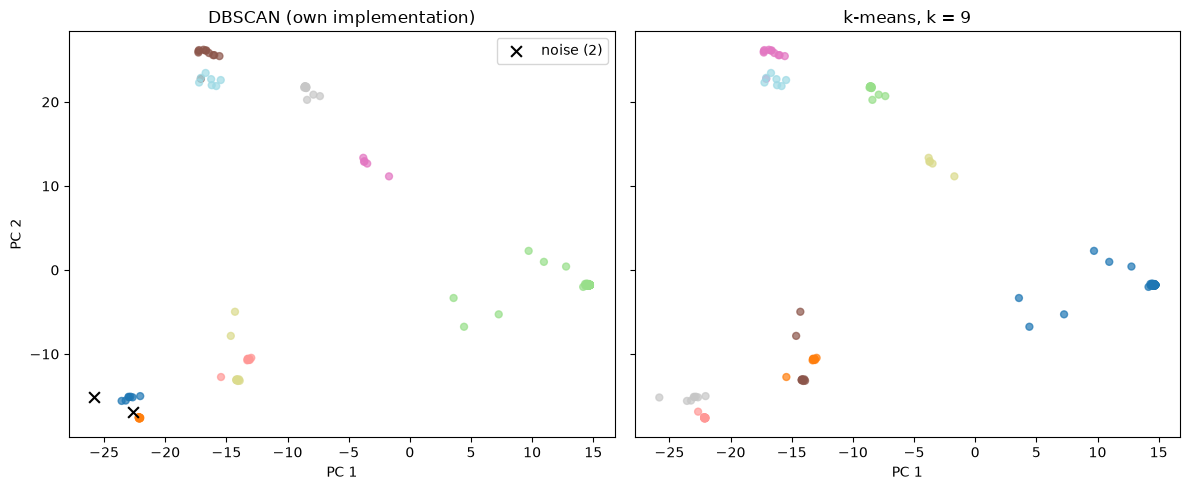

Cluster k-means gives to the DBSCAN noise points:
  MP 18724 (Ind.) -> cluster with {'DF': 7}
  MP 20355 (DD) -> cluster with {'DD': 14}


"k-means, k = 8",0,1,2,3,4,5,6,7
DBSCAN,,,,,,,,
-1: Ind.+DD (2),0,1,0,0,0,0,1,0
0: DF (7),0,0,0,0,0,0,7,0
1: DD (14),0,14,0,0,0,0,0,0
2: S+V (93),93,0,0,0,0,0,0,0
3: LA (14),0,0,0,14,0,0,0,0
4: EL (11),0,0,11,0,0,0,0,0
5: RV (5),0,0,0,0,0,0,0,5
6: SF (16),0,0,0,0,0,16,0,0
7: KF (12),0,0,0,0,12,0,0,0


In [20]:
k = labels_own.max() + 1
fig, axs = plt.subplots(ncols=2, figsize=(12, 5), sharey=True)
plot_labels(axs[0], labels_own, "DBSCAN (own implementation)")
plot_labels(axs[1], kmeans[k], f"k-means, k = {k}")
axs[0].set_ylabel("PC 2")
plt.tight_layout()
plt.show()

print("Cluster k-means gives to the DBSCAN noise points:")
for i in np.flatnonzero(is_noise):
    members = short[(kmeans[k] == kmeans[k][i]) & (short.index != short.index[i])]
    print(f"  MP {X.index[i]} ({short.iloc[i]}) -> cluster with {members.value_counts().to_dict()}")

pd.crosstab(name_clusters(pd.Series(labels_own, index=X.index)), kmeans[8],
            rownames=["DBSCAN"], colnames=["k-means, k = 8"])

- **Same groups.** On the 179 MPs that DBSCAN clusters, k-means with k = 9 gives exactly the same partition (same DBI of 0.417). The only difference is the two noise points, which k-means has to put in DF and DD, raising its DBI to 0.450.
- **DBI prefers k = 8 (0.394)**, which merges EL and ALT. DBSCAN does not win on this index. DBI compares distances to centroids and rewards compact, round clusters, which is what k-means optimises, so we do not use it to choose between the methods.
- **What DBSCAN adds** is that 9 is an output instead of an input, and that it can say "this MP belongs to no group".
- **Why k-means does so well here:** party discipline makes the clusters very tight and far apart, so there is no irregular shape that would need a density-based method.
- **ARI with the parties is only about 0.54** because S, V and M governed together and vote almost identically, so they form one cluster. That is a property of the votes, not a failure of the clustering.
- The scores on `Z` are optimistic for all methods, since filling absent votes from similar MPs pulls similar MPs closer together.

### 3.7 MPs outside their party's cluster
The home cluster of a party is the one containing most of its MPs. We list the MPs who are noise (for DBSCAN on D or on Z) or sit in another cluster, together with all parties they belonged to in the period (in order).

In [21]:
home = pd.crosstab(short, labels_own).drop(index="Ind.", columns=-1).idxmax(axis=1)
parties = df.dropna(subset=["party"]).sort_values("date").groupby("actor")["party"].unique()
out = (labels_own != short.map(home).to_numpy()) | (labels_Z == -1)  # independents have no home, so they are listed too

odd = pd.DataFrame({
    "party":            short[out],
    "cluster":          labels_own[out],
    "parties in it":    [", ".join(pd.unique(short[labels_own == c])) if c >= 0 else "noise" for c in labels_own[out]],
    "noise on Z":       labels_Z[out] == -1,
    "present votes":    N.diagonal()[out].astype(int),
    "closest distance": np.sort(dist, axis=1)[out, 1].round(3),
    "all parties":      [" → ".join(ABBR.get(p, p) for p in parties[a]) for a in X.index[out]],
})
pd.set_option("display.max_colwidth", None)
odd

,party,cluster,parties in it,noise on Z,present votes,closest distance,all parties
actor,,,,,,,
134,RV,2,"S, V, M, RV, Ind.",True,652,0.000,RV → V
17629,V,2,"S, V, M, RV, Ind.",True,569,0.000,V → DD
18723,LA,3,LA,True,732,0.017,Nye Borgerlige → LA
18724,Ind.,-1,noise,True,781,0.266,Nye Borgerlige → Uden for folketingsgrupperne - Lars Boje Mathiesen → Borgernes Parti – Lars Boje Mathiesen
20354,Ind.,8,"ALT, Ind.",False,406,0.000,ALT → Uden for folketingsgrupperne - Theresa Scavenius
20355,DD,-1,noise,True,922,0.041,Nye Borgerlige → Uden for folketingsgrupperne - Kim Edberg Andersen → DD
20381,M,2,"S, V, M, RV, Ind.",True,818,0.000,M → ALT
20383,M,2,"S, V, M, RV, Ind.",True,996,0.000,M → Uden for folketingsgrupperne - Jeppe Søe
20388,Ind.,2,"S, V, M, RV, Ind.",False,918,0.019,M → Uden for folketingsgrupperne - Jon Stephensen


In [22]:
switched = X.index.map(parties).map(len) > 1
print(f"MPs with more than one party in the period: {switched.sum()} of {len(X)}")
print(f"noise on D: {is_noise.sum()}, of which switched: {(is_noise & switched).sum()}")
print(f"noise on Z: {(labels_Z == -1).sum()}, of which switched: {((labels_Z == -1) & switched).sum()}")

MPs with more than one party in the period: 12 of 181
noise on D: 2, of which switched: 2
noise on Z: 8, of which switched: 8


In [23]:
clusters_db = name_clusters(pd.Series(labels_own, index=X.index))
sankey(short[order], clusters_db[order], "Party → DBSCAN cluster")

**What we learn**
- DBSCAN finds the government (S, V, M) as one voting group and each opposition party as its own group.
- All noise points are MPs who **changed party during the period**. They end up between two clusters because their votes mix two parties. Nobody was told who switched.

**Limitations**
- This is not a prediction: the votes after the switch are part of the data. To find MPs who deviated *before* leaving, the analysis should use one row per MP and party (as in Task 4) or only the votes before the switch.
- Four of the listed MPs are independents, who are listed by construction because they have no home cluster.
- The agreement distance compares each pair on different sessions. MP 134 (RV → V) is at distance 0 from two S members who entered parliament late and only share the votes after the switch. This is why DBSCAN on D places this MP in the government cluster while DBSCAN on Z calls it noise. The distance also does not satisfy the triangle inequality, so DBSCAN's chaining has to be read with some care.
- With such strong discipline, no MP who stayed in one party was placed outside the party's cluster. This agrees with the very low dissent rate in Task 4.